# Assignment 2: Stochastic Processes Problem Set

**README:** 
- Install `yfinance numpy pandas matplotlib scipy` (`!pip install yfinance numpy pandas matplotlib scipy`). 
- The notebook downloads the most recent 18 months of daily adjusted closing prices from Yahoo Finance, validates at least 252 daily observations, estimates model parameters, and runs 1,000 paths for 30, 60, and 180 trading days. Prices are adjusted for splits/dividends via `auto_adjust=True`.

In [5]:
!pip install yfinance

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats

TICKER = "AAPL"
N_PATHS = 1000
HORIZONS = (30, 60, 180)
TRADING_DAYS = 252
SEED = 42

Matplotlib is building the font cache; this may take a moment.


AAPL: 378 closes from 2025-04-24 to 2026-10-23
Missing/invalid rows removed: 0; unusual log returns flagged: 1
Date
2026-07-31   -0.076383
Name: AAPL, dtype: float64


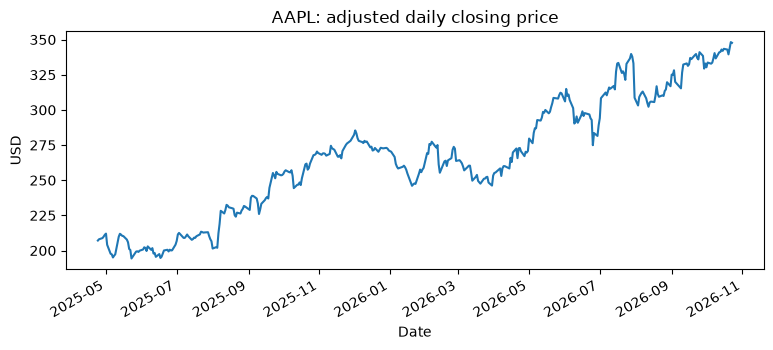

In [5]:
raw = yf.download(TICKER, period="18mo", interval="1d", auto_adjust=True, progress=False)
if raw.empty:
    raise RuntimeError("No market data returned")
close = raw["Close"]
if isinstance(close, pd.DataFrame):
    close = close[TICKER] if TICKER in close.columns else close.iloc[:, 0]
close = pd.to_numeric(close, errors="coerce").sort_index()
close = close[~close.index.duplicated(keep="last")].dropna()
close = close[close > 0]
if len(close) < 252:
    raise ValueError(f"Only {len(close)} clean observations; at least 252 are required.")
log_returns = np.log(close / close.shift(1)).dropna()

flagged = log_returns[abs(log_returns - log_returns.median()) > 6 * 1.4826 * (abs(log_returns - log_returns.median())).median()]
print(f"{TICKER}: {len(close)} closes from {close.index.min().date()} to {close.index.max().date()}")
print(f"Missing/invalid rows removed: {len(raw)-len(close)}; unusual log returns flagged: {len(flagged)}")
print(flagged.head())
close.plot(title=f"{TICKER}: adjusted daily closing price", ylabel="USD", figsize=(9,3.5)); plt.show()


## Models and calibration
Geometric Brownian Motion (GBM): $dS_t=\mu S_tdt+\sigma S_tdW_t$. Estimate annualized log-return mean $m$ and volatility $\sigma$; set $\mu=252m+\sigma^2/2$.

Ornstein–Uhlenbeck Process (OU) on **price levels**: $dS_t=\kappa(\theta-S_t)dt+\eta dW_t$. Estimate daily AR(1) $S_{t+1}=a+bS_t+\epsilon_t$, then $\kappa=-252\ln b$, $\theta=a/(1-b)$, and $\eta=\operatorname{sd}(\epsilon)\sqrt{2\kappa/(1-b^2)}$ (annual-time units). This mapping requires $0<b<1$; otherwise OU is not supported by this calibration and the notebook stops. OU may produce negative prices, so it is a diagnostic comparator, not a preferred stock-price model.

In [6]:
dt = 1 / TRADING_DAYS
s0 = float(close.iloc[-1])
sigma = float(log_returns.std(ddof=1) * np.sqrt(TRADING_DAYS))
mu = float(log_returns.mean() * TRADING_DAYS + 0.5 * sigma**2)
x, y = close.iloc[:-1].to_numpy(), close.iloc[1:].to_numpy()
b, a = np.polyfit(x, y, 1)
if not (0 < b < 1):
    raise ValueError(f"OU calibration is not stable (AR1 slope={b:.5f}). OU is inappropriate for this sample; consider a spread or longer sample.")
kappa = float(-np.log(b) / dt)
theta = float(a / (1 - b))
resid = y - (a + b*x)
eta = float(np.std(resid, ddof=2) * np.sqrt(2*kappa / (1-b*b)))
print(pd.Series(dict(last_price=s0, GBM_mu=mu, GBM_sigma=sigma, OU_kappa=kappa, OU_theta=theta, OU_eta=eta)))


last_price    347.730011
GBM_mu          0.376142
GBM_sigma       0.243845
OU_kappa        0.637617
OU_theta      413.815846
OU_eta         65.772163
dtype: float64


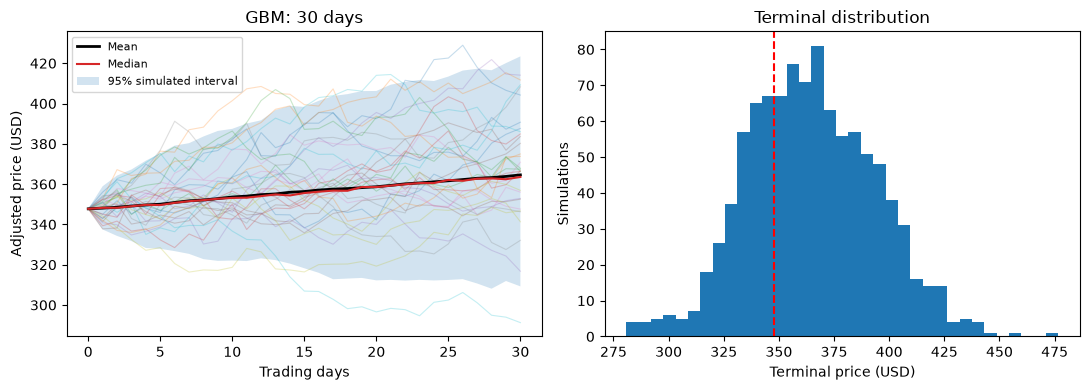

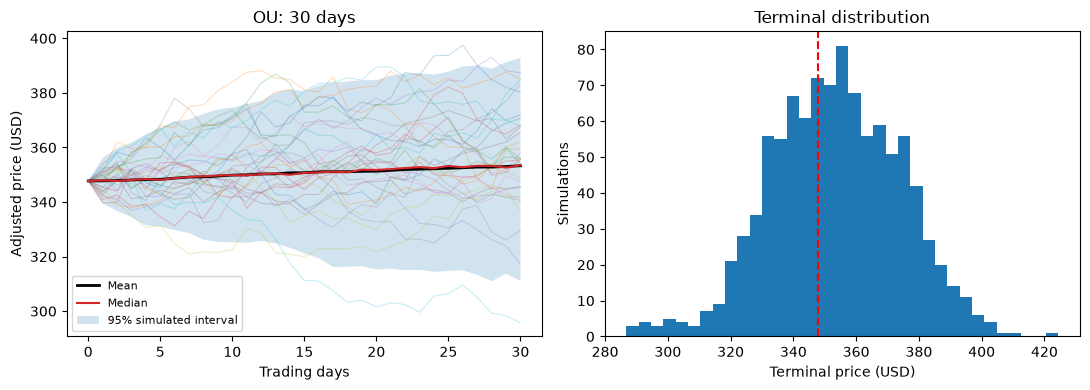

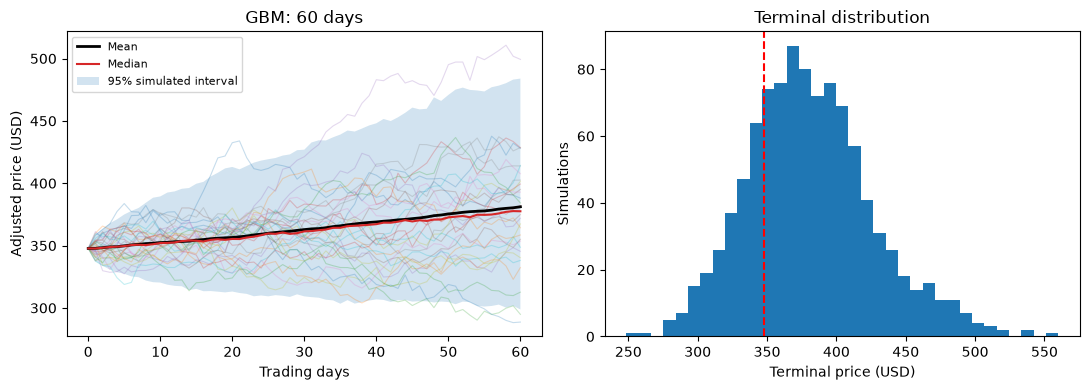

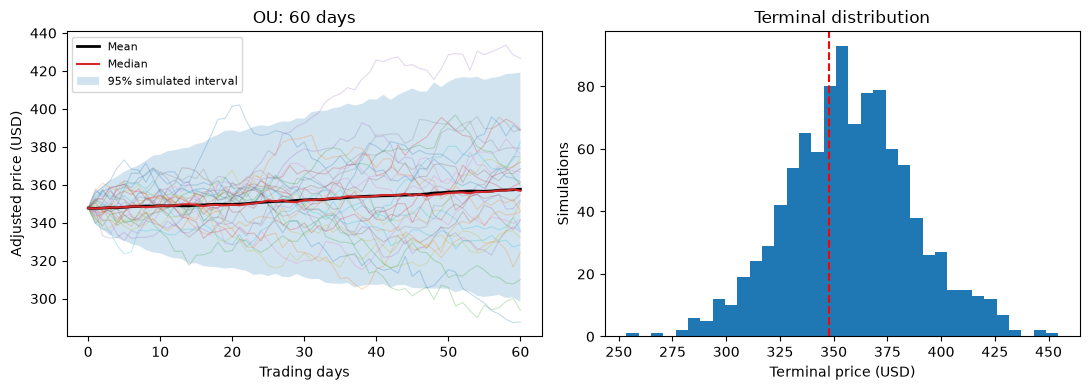

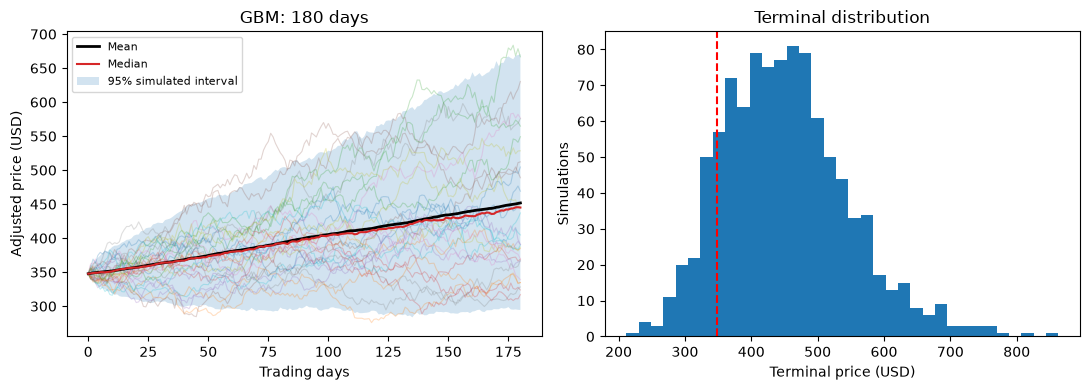

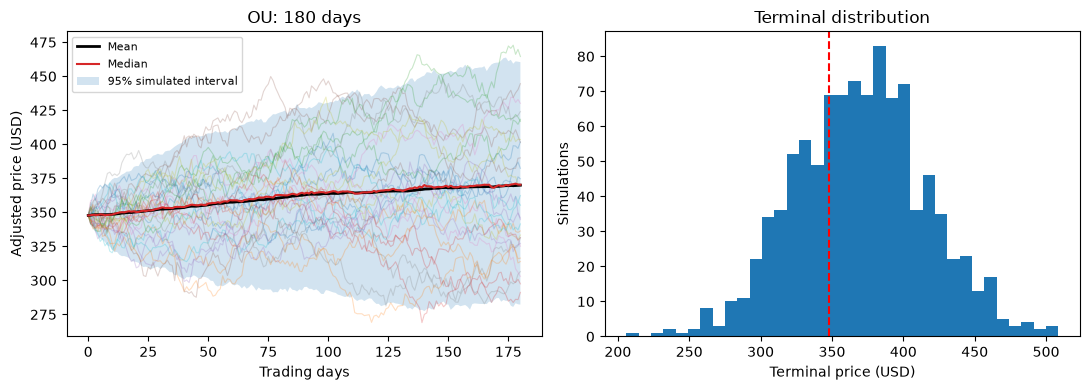

,model,trading_days,mean,median,loss_probability,lower_95,upper_95,negative_price_probability
0,GBM,30,364.572,363.555,0.300,309.243,423.408,0.0
1,OU,30,353.305,353.502,0.398,311.156,392.838,0.0
2,GBM,60,381.127,377.533,0.233,298.795,483.905,0.0
3,OU,60,357.685,356.841,0.365,298.226,419.143,0.0
4,GBM,180,451.784,445.033,0.131,294.499,670.505,0.0
5,OU,180,369.952,370.319,0.308,282.227,460.378,0.0


In [7]:
def simulate_gbm(s0, mu, sigma, steps, n_paths, rng):
    shocks = rng.standard_normal((steps, n_paths))
    log_increments = (mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*shocks
    return np.vstack([np.full(n_paths,s0), s0*np.exp(np.cumsum(log_increments,axis=0))])

def simulate_ou(s0, kappa, theta, eta, steps, n_paths, rng):
    # Exact discretization of OU at each trading-day interval.
    b = np.exp(-kappa*dt)
    sd = eta*np.sqrt((1-b*b)/(2*kappa))
    shocks = rng.standard_normal((steps,n_paths))
    paths = np.empty((steps+1,n_paths)); paths[0]=s0
    for t in range(steps):
        paths[t+1] = theta + (paths[t]-theta)*b + sd*shocks[t]
    return paths

def metrics(paths, initial):
    terminal = paths[-1]
    return dict(mean=float(terminal.mean()), median=float(np.median(terminal)),
                loss_probability=float(np.mean(terminal<initial)),
                lower_95=float(np.quantile(terminal,.025)), upper_95=float(np.quantile(terminal,.975)),
                negative_price_probability=float(np.mean(terminal<=0)))

def visualize(paths, name, horizon):
    fig, ax=plt.subplots(1,2,figsize=(11,4)); t=np.arange(horizon+1)
    ax[0].plot(t,paths[:,:30],alpha=.25,lw=.8)
    ax[0].plot(t,paths.mean(axis=1),color='black',lw=2,label='Mean')
    ax[0].plot(t,np.median(paths,axis=1),color='tab:red',label='Median')
    low,high=np.quantile(paths,[.025,.975],axis=1)
    ax[0].fill_between(t,low,high,alpha=.2,label='95% simulated interval')
    ax[0].legend(fontsize=8);ax[0].set(xlabel='Trading days',ylabel='Adjusted price (USD)',title=f'{name}: {horizon} days')
    ax[1].hist(paths[-1],bins=35);ax[1].axvline(s0,color='red',ls='--')
    ax[1].set(xlabel='Terminal price (USD)',ylabel='Simulations',title='Terminal distribution')
    plt.tight_layout();plt.show()

rows=[]
for h in HORIZONS:
    # Same shock streams by model for a controlled comparison.
    p_gbm=simulate_gbm(s0,mu,sigma,h,N_PATHS,np.random.default_rng(SEED+h))
    p_ou=simulate_ou(s0,kappa,theta,eta,h,N_PATHS,np.random.default_rng(SEED+h))
    for name,p in [('GBM',p_gbm),('OU',p_ou)]:
        rows.append({'model':name,'trading_days':h,**metrics(p,s0)})
        visualize(p,name,h)
results=pd.DataFrame(rows)
display(results.round(3))


## Interpretation and limitations
The results table above comes from **1,000 executed simulated paths per model and horizon**, initialized at the observed adjusted closing price of **$347.73** on 2026-10-23.

| Model | Trading days | Terminal mean ($) | Median ($) | Simulated loss fraction | 95% terminal interval ($) |
|:--|--:|--:|--:|--:|:--|
| GBM | 30 | 364.572 | 363.555 | 0.300 | 309.243–423.408 |
| OU | 30 | 353.305 | 353.502 | 0.398 | 311.156–392.838 |
| GBM | 60 | 381.127 | 377.533 | 0.233 | 298.795–483.905 |
| OU | 60 | 357.685 | 356.841 | 0.365 | 298.226–419.143 |
| GBM | 180 | 451.784 | 445.033 | 0.131 | 294.499–670.505 |
| OU | 180 | 369.952 | 370.319 | 0.308 | 282.227–460.378 |

The simulated probability of loss is the fraction of terminal prices **below $347.73**. No sampled terminal price was nonpositive in any run; this does not eliminate the theoretical possibility under OU. GBM produces higher mean prices and a wider upper tail at 180 days, driven partly by its estimated positive drift; OU pulls toward its fitted $413.82 equilibrium. Neither model is validated against unseen observations.

### Limitations and investment relevance
The historical sample spans approximately 18 months and contains one flagged extreme daily return, which was retained. Model parameters are treated as fixed, and simulations exclude transaction costs, changes in volatility, structural breaks, dividends as cash flows, and estimation uncertainty. GBM assumes constant drift and volatility; OU imposes mean reversion in a nonstationary-looking stock price level and can generate negative prices. The 95% bands are conditional simulated predictive ranges, not confidence intervals for parameters and not guaranteed coverage. These results are scenario analyses rather than buy/sell signals. Consider multiple models, independent risk controls, and out-of-sample validation before using them for investment decisions.

## Sources 
Yahoo Finance market data via `yfinance`; Øksendal (2003); Uhlenbeck & Ornstein (1930); Merton (1976).